## Cleaning (Q1–8)



1. Load the file into df. Print shape and dtypes.


In [2]:
import pandas as pd
df = pd.read_csv('meridian_daily_sales_raw - meridian_daily_sales_raw.csv.csv')
print("Shape: ", df.shape)
print("Data type: ", df.dtypes)

Shape:  (1627, 10)
Data type:  store_id             object
store_name           object
region               object
date                 object
transactions          int64
revenue              object
avg_basket_value    float64
discount_pct         object
footfall              int64
stockout_flag        object
dtype: object


transactions is int64 data type, avg_basket_value is float64 and rest is object data type

2. Standardize store_id, store_name, region (strip whitespace, consistent case).


In [3]:
df['store_id'] = df['store_id'].str.strip()
df['store_name'] = df['store_name'].str.strip().str.lower().str.replace(' ', '_')
df['region'] = df['region'].str.strip().str.lower().str.replace(' ', '_')

print("Store Ids: ",df['store_id'].unique())
print("Store Names: ",df['store_name'].unique())
print("Store region: ",df['region'].unique())


Store Ids:  ['ST-10' 'ST-13' 'ST-16' 'ST-14' 'ST-04' 'ST-12' 'ST-08' 'ST-11' 'ST-18'
 'ST-01' 'ST-05' 'ST-17' 'ST-15' 'ST-03' 'ST-06' 'ST-02' 'ST-09' 'ST-07']
Store Names:  ['magnolia_square' 'highland_court' 'redwood_station' 'golden_valley'
 'silverline_mall' 'bayfront_commons' 'palm_terrace' 'willow_creek'
 'ashbrook_plaza' 'riverside_plaza' 'eastgate_center' 'summit_corner'
 'pinecrest_mall' 'maple_junction' 'cedar_crossing' 'harbor_point'
 'coral_bay_outlet' 'sunset_boulevard']
Store region:  ['south' 'west' 'north']


Starting and trailing spaces are removed from store_id column.

In store_name and region column first starting and trailing spaces are removed
then converted to lower case and space is relaced with underscore.

3. Parse date into a real date column. Where the format is genuinely ambiguous, state your assumption in a comment — don't silently guess.


In [4]:
df['date'] = pd.to_datetime(df['date'], format='mixed')


date format is set to mixed because becasue there is no perticular format of date in the column

In [5]:
# 4. Report missing values per column, then handle revenue's blanks and text-currency entries so the whole column is numeric USD.
missing_values = df.isna().sum()
print("Missing values: \n",missing_values)

df['revenue'] = df['revenue'].str.replace(',', '').str.replace('$', '').str.replace('INR', '').astype(float)
df["revenue"].map(type).value_counts()


Missing values: 
 store_id             0
store_name           0
region               0
date                 0
transactions         0
revenue             53
avg_basket_value     0
discount_pct         0
footfall             0
stockout_flag        0
dtype: int64


,count
revenue,
<class 'float'>,1627


There are 53 missing values in revenue column.
The revenue column is converted to float.

5. Standardize stockout_flag to boolean.


In [6]:
stockout_map = {
    "y": True,
    "yes": True,
    "1": True,
    "true": True,
    "n": False,
    "no": False,
    "0": False,
    "false": False
}

df["stockout_flag"] = (
    df["stockout_flag"]
    .str.lower()
    .map(stockout_map)
)

df['stockout_flag'].unique()


array([False,  True])

The stockout_flag column is converted to boolean data type.

6. Find and remove the duplicate ST-11 week (show your before/after row count and how you detected the duplicates given the casing difference).


In [7]:
print("no of rows before duplicates: ", df.shape[0])
df[df.duplicated()]

df = df.drop_duplicates()

print("no of rows after removing duplicates: ", df.shape[0])



no of rows before duplicates:  1627
no of rows after removing duplicates:  1620


there were 7 duplicate rows and are deleted

7. Flag transactions < 0 and discount_pct outside [0, 100] as data-entry errors. Decide and justify: drop, cap, or leave for outlier analysis?


In [8]:
df["transaction_error"] = df["transactions"] < 0

df["discount_pct"] = pd.to_numeric(df["discount_pct"], errors="coerce")
df["discount_error"] = ~df["discount_pct"].between(0, 100)

df["data_entry_error"] = ( df["transaction_error"] | df["discount_error"])

errors = df[df["data_entry_error"]]
print(errors)

df["data_entry_error"].value_counts()



     store_id        store_name region       date  transactions  revenue  \
4       ST-04   silverline_mall  north 2026-04-03           -52  2733.73   
41      ST-12  bayfront_commons  south 2026-03-24            52  5648.15   
70      ST-06    cedar_crossing  north 2026-05-24            36  6702.05   
71      ST-09  coral_bay_outlet  south 2026-03-26            81  4601.00   
75      ST-01   riverside_plaza  north 2026-05-09            42  6025.00   
...       ...               ...    ...        ...           ...      ...   
1550    ST-16   redwood_station   west 2026-01-05           -41  5830.68   
1585    ST-03    maple_junction  north 2026-03-10            91  8139.00   
1587    ST-08      palm_terrace  south 2026-05-09            60  2315.93   
1611    ST-10   magnolia_square  south 2026-01-05            51  4965.35   
1616    ST-04   silverline_mall  north 2026-04-30            67  3050.22   

      avg_basket_value  discount_pct  footfall  stockout_flag  \
4              2796.60

,count
data_entry_error,
False,1536
True,84


There are 84 records which has data entry error.

These records need further investigation so leaving it for outlier analysis

8. Save a cleaned CSV. Report final row count.


In [9]:
print("row count: ",df.shape[0])
df.to_csv("partA_meridian_cleaned_data.csv", index=False)


row count:  1620


total row count is 1620 and file is saved as cleaned_data.csv

## Quartiles & IQR outliers (Q9–16)


9. Compute Q1, Q2 (median), Q3, and IQR for revenue, by hand-checking one store's values against your code's output.


In [10]:

store_id = 'ST-10'
print("For store: ", store_id)
df_st10_revenue = df[df['store_id'] == store_id]['revenue']

Q1_st10 = df_st10_revenue.quantile(0.25)
Q2_st10 = df_st10_revenue.median()
Q3_st10 = df_st10_revenue.quantile(0.75)
IQR_st10 = Q3_st10 - Q1_st10

print(f"Q1: {Q1_st10:.2f}")
print(f"Q2: {Q2_st10:.2f}")
print(f"Q3: {Q3_st10:.2f}")
print(f"IQR: {IQR_st10:.2f}")

display(df_st10_revenue.describe())

For store:  ST-10
Q1: 3240.20
Q2: 4438.76
Q3: 5559.32
IQR: 2319.12


,revenue
count,88.000000
mean,4743.210682
std,1920.532050
min,2010.670000
25%,3240.200000
50%,4438.760000
75%,5559.325000
max,11228.010000


I have taken "ST-10" store and calculated its  Q1, Q2 (median), Q3 and IQR

 10. Compute the 1.5×IQR lower and upper fences for revenue.


In [11]:

Q1_revenue = df['revenue'].quantile(0.25)
Q3_revenue = df['revenue'].quantile(0.75)
IQR_revenue = Q3_revenue - Q1_revenue

lower_fence = Q1_revenue - (1.5 * IQR_revenue)
upper_fence = Q3_revenue + (1.5 * IQR_revenue)

print(f"Lower Fence for revenue: {lower_fence:.2f}")
print(f"Upper Fence for revenue: {upper_fence:.2f}")

Lower Fence for revenue: -1399.54
Upper Fence for revenue: 11899.30


lower and upper fence for revenue is -1399.54 and 11899.30

11. List every row flagged as an outlier by the fence rule. How many, and which stores/dates?


In [12]:

outliers_revenue = df[(df['revenue'] < lower_fence) | (df['revenue'] > upper_fence)]

print(f"Number of revenue outliers: {len(outliers_revenue)}")
print("Outlier details:")

display(outliers_revenue[['store_id', 'date', 'revenue']])

Number of revenue outliers: 68
Outlier details:


,store_id,date,revenue
23,ST-09,2026-04-14,13995.56
46,ST-11,2026-05-18,14158.45
55,ST-09,2026-05-27,14698.87
66,ST-12,2026-04-13,13706.20
101,ST-07,2026-05-02,16688.90
...,...,...,...
1477,ST-09,2026-05-14,12747.03
1483,ST-12,2026-04-08,14992.75
1486,ST-07,2026-05-12,16406.55
1548,ST-12,2026-04-01,15876.48


There are 68 records identified as outlier the details are printed.

12. Do the same fence calculation for footfall. Does it catch the ~40,000 sensor-fault days?


In [13]:
Q1_footfall = df['footfall'].quantile(0.25)
Q3_footfall = df['footfall'].quantile(0.75)
IQR_footfall = Q3_footfall - Q1_footfall

lower_fence_footfall = Q1_footfall - (1.5 * IQR_footfall)
upper_fence_footfall = Q3_footfall + (1.5 * IQR_footfall)

print(f"Lower fence: {lower_fence_footfall:.2f}")
print(f"Upper fence: {upper_fence_footfall:.2f}")

outliers_footfall = df[(df['footfall'] < lower_fence_footfall) | (df['footfall'] > upper_fence_footfall)]

print(f" outliers: {len(outliers_footfall)}")
print("Outlier details")
display(outliers_footfall[['store_id', 'date', 'footfall']])

if any(outliers_footfall['footfall'].between(39000, 41000)):
    print("Yes")
else:
    print("No")

Lower fence: 189.00
Upper fence: 1007.00
 outliers: 9
Outlier details


,store_id,date,footfall
145,ST-14,2026-03-24,1033
165,ST-02,2026-04-21,185
330,ST-15,2026-04-17,121
978,ST-09,2026-04-03,41631
1012,ST-14,2026-05-10,1045
1088,ST-09,2026-03-15,39530
1164,ST-06,2026-03-24,1083
1189,ST-09,2026-05-21,41562
1283,ST-06,2026-04-16,165


Yes


Yes, some footfall outliers are around 40,000 may be sensor-fault days.

13. Draw a box plot of revenue by region. Which region has the widest IQR, and what does that mean in plain English?


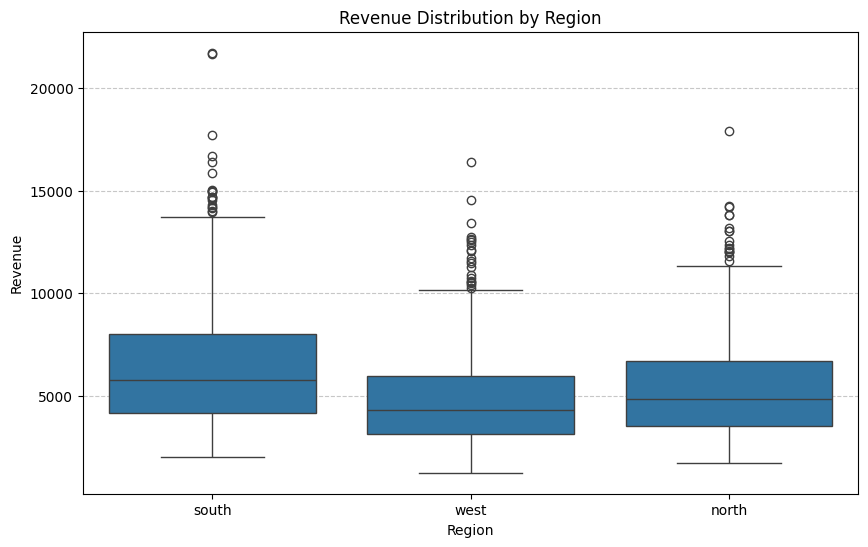

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.boxplot(x='region', y='revenue', data=df)
plt.title('Revenue Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Revenue')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Calculate IQR for each region
iqr_by_region = df.groupby('region')['revenue'].apply(lambda x: x.quantile(0.75) - x.quantile(0.25))

widest_iqr_region = iqr_by_region.idxmax()
max_iqr_value = iqr_by_region.max()


The region with the widest IQR is **south** with an IQR of 3854.82.

A wider IQR for south means that the middle 50% of revenue values for stores in this region are more spread out or diverse compared to other regions. It indicates greater variability in daily revenue for south stores

14. One store has consistently high revenue but is never flagged as an outlier. Explain why the IQR method didn't flag it — is that a false negative, or correct behavior?


Consistently high revenue values are not necessarily outliers. If they cluster within the dataset lower and upper IQR fences, the method treats them as part of the normal distribution. This is expected IQR detects statistically unusual values, not consistently high performance.

15. Recompute the fences after removing the sensor-fault footfall days. How much do the fences shift? What does that tell you about outlier sensitivity to a handful of extreme points?


In [15]:
df_no_footfall_outliers = df.drop(outliers_footfall.index)

Q1_footfall_cleaned = df_no_footfall_outliers['footfall'].quantile(0.25)
Q3_footfall_cleaned = df_no_footfall_outliers['footfall'].quantile(0.75)
IQR_footfall_cleaned = Q3_footfall_cleaned - Q1_footfall_cleaned

new_lower_fence_footfall = Q1_footfall_cleaned - (1.5 * IQR_footfall_cleaned)
new_upper_fence_footfall = Q3_footfall_cleaned + (1.5 * IQR_footfall_cleaned)

print(f"Original Lower Fence: {lower_fence_footfall:.2f}")
print(f"Original Upper Fence: {upper_fence_footfall:.2f}")
print(f"\nNew Lower Fence (without outliers): {new_lower_fence_footfall:.2f}")
print(f"New Upper Fence (without outliers): {new_upper_fence_footfall:.2f}")

shift_lower = new_lower_fence_footfall - lower_fence_footfall
shift_upper = new_upper_fence_footfall - upper_fence_footfall

print(f"\nShift in Lower Fence: {shift_lower:.2f}")
print(f"Shift in Upper Fence: {shift_upper:.2f}")

Original Lower Fence: 189.00
Original Upper Fence: 1007.00

New Lower Fence (without outliers): 190.75
New Upper Fence (without outliers): 1004.75

Shift in Lower Fence: 1.75
Shift in Upper Fence: -2.25


The small change in IQR fences after removing extreme sensor-fault days shows that the method is robust to few outliers. Because fences depend mainly on the median and middle 50% of the data, rare extreme values have limited influence, though the upper fence may shift slightly. Significant changes occur only when outliers are numerous enough to affect the quartiles.

16. Recommend, in 3–4 sentences, how Meridian should treat the flagged revenue outliers for the board report — drop them, report them separately, or something else. Justify with the actual numbers.


Meridian should report the flagged revenue outliers separately rather than dropping them. There are 68 such outliers, representing days with unusually high or low revenue compared to the rest of the data. While statistically unusual, these extreme events could provide valuable insights into exceptional sales days or potential data anomalies that need further investigation.

## Skewness & shape (Q17–22)

17. Compute mean, median, and mode of revenue. Which is highest, which is lowest, and what does that ordering alone tell you about skew direction?


In [16]:
mean_revenue = df['revenue'].mean()
median_revenue = df['revenue'].median()
mode_revenue = df['revenue'].mode()[0]

print(f"Mean of Revenue: {mean_revenue:.2f}")
print(f"Median of Revenue: {median_revenue:.2f}")
print(f"Mode of Revenue: {mode_revenue:.2f}")

metrics = {'Mean': mean_revenue, 'Median': median_revenue, 'Mode': mode_revenue}
max_metric = max(metrics, key=metrics.get)
min_metric = min(metrics, key=metrics.get)

print(f"\nHighest: {max_metric} ({metrics[max_metric]:.2f})")
print(f"Lowest: {min_metric} ({metrics[min_metric]:.2f})")


Mean of Revenue: 5613.18
Median of Revenue: 4914.94
Mode of Revenue: 3258.00

Highest: Mean (5613.18)
Lowest: Mode (3258.00)


Since Mean > Median > Mode, the distribution is likely right-skewed or positively skewed.

18. Compute the skewness coefficient of revenue. Is it right- or left-skewed, and roughly how strong (mild/moderate/strong)?


In [17]:
skewness_revenue = df['revenue'].skew()
print(f"Skewness coefficient of Revenue: {skewness_revenue:.2f}")


Skewness coefficient of Revenue: 1.38


The revenue distribution is right-skewed (positively skewed) and is strongly skewed.

19. Plot a histogram of revenue with the mean and median both marked. Does the picture agree with Q17–18?

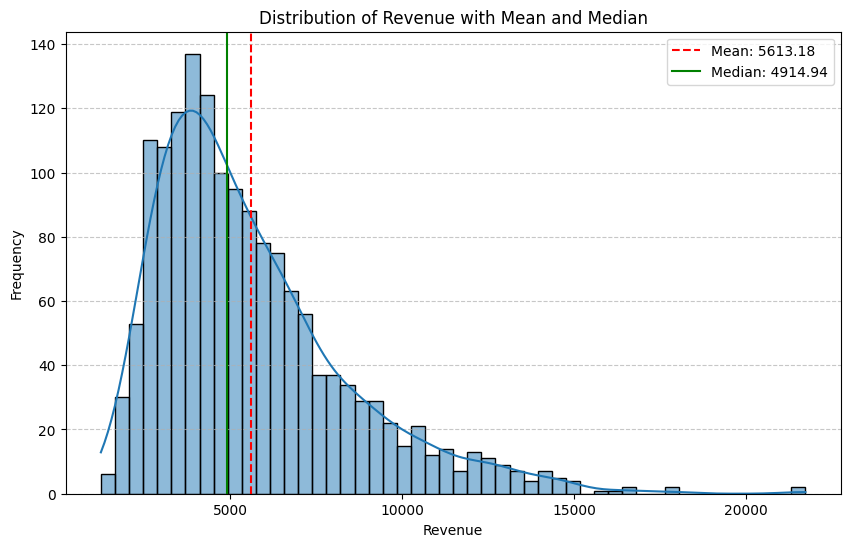

In [18]:
plt.figure(figsize=(10, 6))
sns.histplot(df['revenue'], kde=True, bins=50)
plt.axvline(mean_revenue, color='red', linestyle='--', label=f'Mean: {mean_revenue:.2f}')
plt.axvline(median_revenue, color='green', linestyle='-', label=f'Median: {median_revenue:.2f}')
plt.title('Distribution of Revenue with Mean and Median')
plt.xlabel('Revenue')
plt.ylabel('Frequency')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The histogram shows a long tail to the right, mean (red dashed line) positioned to the right of the median (green solid line).

This visual representation agrees with the numerical findings from Q17 and Q18.

20. Finance's board deck currently reports "average daily basket value." Given the skew, is the mean or the median a fairer single number to report? Justify in 2–3 sentences.


In [19]:

print(f"Mean: {df['avg_basket_value'].mean():.2f}")
print(f"Median: {df['avg_basket_value'].median():.2f}")
print(f"Skewness: {df['avg_basket_value'].skew():.2f}")

Mean: 159.31
Median: 85.96
Skewness: 14.25


Both revenue and likely avg_basket_value are right-skewed, the **median** would be a fairer single number to report for average daily basket value.

The mean which is 159.31 is heavily influenced by high-value outliers, which can inflate the average and misrepresent the daily basket value.

The median 85.96 ,which is resistant to extreme values, provides better central tendency so is good for daily basket value in this case.

21. Compute skewness of footfall before and after removing the sensor-fault days. How much does skew change?


In [20]:

skewness_footfall_original = df['footfall'].skew()
print(f"Original Skewness of Footfall: {skewness_footfall_original:.2f}")

skewness_footfall_cleaned = df_no_footfall_outliers['footfall'].skew()
print(f"Skewness of Footfall (cleaned): {skewness_footfall_cleaned:.2f}")

change_in_skew = skewness_footfall_cleaned - skewness_footfall_original
print(f"\nChange in Skewness: {change_in_skew:.2f}")

Original Skewness of Footfall: 22.96
Skewness of Footfall (cleaned): 0.02

Change in Skewness: -22.93


Removing the sensor-fault days caused a noticeable change in the skewness of footfall.

### 22. Explain to a non-technical store manager (no formulas) what "right-skewed" means for their daily revenue, using one concrete number from the data.

Right-skewed means that most days your store earns a relatively modest amount, but a small number of exceptionally busy days maybe during festivals bring in much more money. Those unusually high-revenue days pull the average upward, so the average is higher than what you typically earn.

For example  4,914.94 is your true typical day revenue which means  half of your days earn less than this, and half earn more. The average 5,613.18 gets inflated by those few exceptional high-earning days like in festivals etc.

## Synthesis

23. Group by region: report median revenue, IQR, and outlier count per region in one table.





In [21]:
# Group by region and compute stats
def summarize(group):
    q1, median, q3 = group.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((group < lower) | (group > upper)).sum()
    return pd.Series({
        'median_revenue': round(median, 2),
        'iqr': round(iqr, 2),
        'outlier_count': outliers
    })

result = df.groupby('region')['revenue'].apply(summarize).unstack()
print(result)

        median_revenue      iqr  outlier_count
region                                        
north          4861.09  3157.88           17.0
south          5759.32  3854.82           19.0
west           4287.35  2828.20           21.0


24. Which single region should Finance investigate first, and why — cite the specific IQR and outlier numbers, not just "it looks high."


In [22]:
regional_stats_numeric = df.groupby('region')['revenue'].agg(
    median_revenue='median',
    Q1_revenue=lambda x: x.quantile(0.25),
    Q3_revenue=lambda x: x.quantile(0.75)
).reset_index()
regional_stats_numeric['IQR'] = regional_stats_numeric['Q3_revenue'] - regional_stats_numeric['Q1_revenue']

regional_stats_numeric['outlier_count'] = regional_stats_numeric['region'].apply(lambda r:
    len(df[(df['region'] == r) & ((df['revenue'] < lower_fence) | (df['revenue'] > upper_fence))])
)

widest_iqr_region = regional_stats_numeric.loc[regional_stats_numeric['IQR'].idxmax()]

most_outliers_region = regional_stats_numeric.loc[regional_stats_numeric['outlier_count'].idxmax()]
print(widest_iqr_region['region'], widest_iqr_region['IQR'], widest_iqr_region['outlier_count'])

south 3854.825 43


Based on the analysis, the 'south' region should be investigated first. This region exhibits the widest Interquartile Range for revenue, at $3854.82. A high IQR indicates significant variability in daily revenue, suggesting inconsistent performance or a wider range of typical sales compared to other regions. Furthermore, it also has a notable number of revenue outliers: 43 days, which merit closer examination to understand the underlying causes of both extreme highs and lows.



### 25. Executive Summary: Meridian Daily Sales Analysis

Initial review of Meridian's daily sales data revealed several critical insights. Data cleaning addressed inconsistencies in formatting and duplicate entries, ensuring a reliable foundation for analysis.

We identified 68 revenue outliers, representing days with unusually high or low sales, which we recommend reporting separately to the board for deeper insight rather than simply removing them. While the footfall data showed 9 extreme 'sensor-fault' days, their removal only minimally affected our outlier detection fences, demonstrating the robustness of the IQR method to such extreme but sparse anomalies.

Lastly, we found that revenue is strongly right-skewed, indicating many days with lower sales but a few with exceptionally high revenue. For reporting, the median revenue of approximately 4914.94 is a fairer representation of typical daily performance than the mean, as it is less influenced by these infrequent high-revenue days. The 'south' region shows the highest revenue variability (IQR of 3854.82) and also the highest number of revenue outliers, making it the primary candidate for further financial investigation into its sales patterns.